# Лабораторная работа №1. Исследование KNN

**Цель работы:** исследовать алгоритм k ближайших соседей в задачах классификации и регрессии,
оценить влияние предобработки и гиперпараметров, сопоставить sklearn с собственной реализацией.

Выбраны два набора данных:

- **Классификация:** [Loan Approval Classification Data, Kaggle](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data), цель `loan_status`.
- **Регрессия:** [Concrete Compressive Strength, UCI №165](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength), цель `strength`, МПа.

Выбор соответствует требованию уникальности датасетов среди участников группы.
Работа включает постановку задач, анализ данных, исходные модели, проверку гипотез улучшения,
собственную реализацию KNN и сравнение результатов.

## 1. Начальные условия

**Классификация.** Рассматривается прогноз исторического статуса кредитной заявки по данным клиента и условиям запроса:
`loan_status=1` — одобрено, `0` — отказ. Практическая задача — предварительная обработка заявок.
Это прогноз статуса заявки, а не вероятности будущего дефолта. Цель и `loan_int_rate` исключены из входов:
ставка может назначаться позднее, выбран сценарий до её назначения. Доля суммы в доходе остаётся входом,
поскольку сумма и доход известны на этапе заявки.

Синтетический набор из 45 000 строк содержит числовые и категориальные признаки. По описанию автора он
расширен SMOTENC; родство синтетических объектов между train/test проверить без идентификаторов генерации нельзя.
Модель исследует свойства KNN и не проверена для принятия реальных банковских решений.

**Регрессия.** Рассматривается прогноз прочности бетона при сжатии по количеству семи компонентов смеси (кг/м³)
и возрасту образца (дни). Практическая цель — предварительная оценка прочности при подборе рецептуры
и планировании испытаний. В исходном UCI-наборе 1030 лабораторных измерений, восемь входов,
цель — `strength` в МПа. Целевая переменная не преобразуется. Это исходная регрессионная постановка UCI.

**Метрики.** Для классификации основной критерий выбора — F1 положительного класса, учитывающий precision
и recall при дисбалансе. Дополнительно используются precision, recall, balanced accuracy, accuracy, ROC-AUC,
average precision. Accuracy сама по себе может скрыть пропуск редкого класса. Для AP доля положительных
служит ориентиром случайного ранжирования. Решение о классе определяется большинством голосов соседей.
Для регрессии основная метрика — MAE в МПа: она даёт понятную среднюю абсолютную ошибку. RMSE усиливает вклад
крупных ошибок, R² оценивает объяснённую вариацию и может быть отрицательным.

**Разбиения.** Seed=42. Для классификации — 80/20 со стратификацией и 3-fold StratifiedKFold на train.
Для бетона удалены точные дубликаты полных строк. Измерения одной рецептуры
(семь компонентов **без возраста и без цели**) объединены в группы. GroupShuffleSplit оставляет 20% рецептур
для test, поэтому доля строк test может отличаться от 20%. Одна рецептура в разных возрастах не попадает
одновременно в train/test. CV — 3-fold GroupKFold только на train с теми же группами.
Это проверяет прогноз для новых рецептур, а не узнавание уже виденной смеси в другом возрасте.

EDA проводится только на train. Imputer, scaler и encoder обучаются внутри Pipeline отдельно в каждом фолде.
Представление и параметры выбираются по CV, test применяется после фиксации настроек.
Последовательный выбор preprocessing и параметров на тех же фолдах может завысить CV;
поэтому итоговое качество оценивается на отложенной выборке.

### Окружение и библиотеки
Использованы NumPy, pandas, scikit-learn и библиотеки визуализации.
Число вычислительных потоков ограничено для сопоставимого измерения времени.

In [1]:
# Все вычисления выполняются Python из lab_1/.venv; ограничиваем параллелизм.
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/vkr_matplotlib")
import sys
import json
import platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GroupShuffleSplit, GroupKFold, cross_val_score, GridSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
LAB = Path.cwd() if (Path.cwd() / "src" / "experiment.py").exists() else Path.cwd() / "lab_1"
sys.path.insert(0, str(LAB))
from src.experiment import SEED, DATASETS, EXCLUDED, sha256, load_dataset, make_pipeline, evaluate
thread_limit = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid")
RESULTS = LAB / "results"
RESULTS.mkdir(exist_ok=True)
print({"python": platform.python_version(), "executable": sys.executable,
       "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__})

{'python': '3.12.3', 'executable': '/home/sergey/workspace/vkr/lab_1/.venv/bin/python', 'numpy': '2.5.4', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Загрузка данных и формирование выборок
Исходные файлы проверены по SHA256 и ожидаемым размерам. Столбцам бетона присвоены короткие имена
в исходном порядке UCI; численные значения сохранены. Точные дубликаты удалены до разделения данных.
Разбиение кредитных заявок стратифицировано по целевому классу, а измерения бетона разделены по рецептурам.

In [2]:
# Оба исходных файла включены в репозиторий; загрузчик проверяет SHA256.
tasks, datasets, split_records = {}, {}, []
targets = {task: spec["target"] for task, spec in DATASETS.items()}
for task, spec in DATASETS.items():
    raw = load_dataset(LAB, task)
    duplicates = int(raw.duplicated().sum())
    data = raw.drop_duplicates().copy()
    X, y = data.drop(columns=spec["excluded"]), data[spec["target"]]
    if task == "classification":
        assert set(y.unique()) == {0, 1}
        train_idx, test_idx = train_test_split(data.index.to_numpy(), test_size=.2,
                                              random_state=SEED, stratify=y)
        groups = pd.Series(data.index.to_numpy(), index=data.index)
    else:
        recipe_columns = [column for column in X if column != "age"]
        groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X[recipe_columns]))[0], index=data.index)
        a, b = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED).split(X, y, groups))
        train_idx, test_idx = data.index.to_numpy()[a], data.index.to_numpy()[b]
    assert set(train_idx).isdisjoint(test_idx)
    assert set(groups.loc[train_idx]).isdisjoint(groups.loc[test_idx])
    split = pd.DataFrame({"row_id": np.concatenate([train_idx, test_idx]),
                          "split": ["train"] * len(train_idx) + ["test"] * len(test_idx),
                          "group_id": pd.concat([groups.loc[train_idx], groups.loc[test_idx]]).to_numpy()})
    split_path = RESULTS / f"split_{task}.csv"
    split.to_csv(split_path, index=False)
    split_records.append(split.assign(task=task, dataset=spec["name"]))
    tasks[task] = dict(X_train=X.loc[train_idx], X_test=X.loc[test_idx],
                       y_train=y.loc[train_idx], y_test=y.loc[test_idx],
                       groups_train=groups.loc[train_idx], groups_test=groups.loc[test_idx],
                       train_idx=train_idx, test_idx=test_idx, duplicates_removed=duplicates,
                       split_sha=sha256(split_path), spec=spec)
    datasets[task] = data
    print(f"{task}: {spec['name']}; raw={len(raw)}, дубликаты={duplicates}, "
          f"train={len(train_idx)}, test={len(test_idx)}, доля test={len(test_idx)/len(data):.3f}")
    if task == "regression":
        print(f"Рецептур train={groups.loc[train_idx].nunique()}, test={groups.loc[test_idx].nunique()}")
    display(pd.DataFrame({"target": [spec["target"]], "excluded": [spec["excluded"]],
                          "dataset_sha": [spec["sha256"]], "split_sha": [sha256(split_path)]}))
pd.concat(split_records, ignore_index=True).to_csv(RESULTS / "split.csv", index=False)

classification: Loan Approval Classification Data; raw=45000, дубликаты=0, train=36000, test=9000, доля test=0.200


,target,excluded,dataset_sha,split_sha
0,loan_status,"[loan_status, loan_int_rate]",67cca604cd71cbd605014f721d078d20d44d726d625945...,7b361ef3c2f6064122c71a7ef24d5d1665daf47a3d17fc...


regression: Concrete Compressive Strength; raw=1030, дубликаты=25, train=799, test=206, доля test=0.205
Рецептур train=342, test=86


,target,excluded,dataset_sha,split_sha
0,strength,[strength],710076c66b9ca3f8050e7942f3dcbdbe04013534daeb00...,d91bd7e186c5164a58c7d569eb2e616e9a5cfcf03e6677...


### Разведочный анализ обучающих данных
Рассмотрены типы признаков, пропуски, описательные статистики, распределения и корреляции.
В кредитных данных отмечены подозрительные значения возраста и стажа. Без подтверждения их ошибочности
эти наблюдения сохранены. Для бетона рассмотрена связь возраста с прочностью.
Отложенные выборки в разведочном анализе не использованы.

classification Loan Approval Classification Data


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
6048,24.0,male,Master,58914.0,2,OWN,4400.0,VENTURE,5.99,0.07,4.0,656,Yes,0
3346,23.0,female,High School,45873.0,2,RENT,11000.0,VENTURE,11.01,0.24,2.0,634,Yes,0
17998,29.0,female,Master,240947.0,7,MORTGAGE,10000.0,VENTURE,12.69,0.04,9.0,638,Yes,0
24988,30.0,female,Bachelor,96316.0,10,MORTGAGE,6000.0,MEDICAL,13.49,0.06,8.0,682,No,0
23231,29.0,male,Bachelor,73033.0,7,MORTGAGE,8000.0,PERSONAL,10.51,0.11,8.0,644,Yes,0


,type,missing,unique
person_age,float64,0,58
person_gender,str,0,2
person_education,str,0,5
person_income,float64,0,28534
person_emp_exp,int64,0,61
person_home_ownership,str,0,4
loan_amnt,float64,0,3742
loan_intent,str,0,6
loan_int_rate,float64,0,1277
loan_percent_income,float64,0,64


,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,36000.00,36000.00,36000.00,36000.00,36000.00,36000.00,36000.00,36000.00,36000.00
mean,27.76,80549.47,5.41,9586.96,11.01,0.14,5.86,632.65,0.22
std,6.05,84316.97,6.06,6301.45,2.98,0.09,3.88,50.29,0.42
min,20.00,8000.00,0.00,500.00,5.42,0.00,2.00,390.00,0.00
25%,24.00,47163.50,1.00,5000.00,8.59,0.07,3.00,602.00,0.00
50%,26.00,67081.00,4.00,8000.00,11.01,0.12,4.00,640.00,0.00
75%,30.00,96260.75,8.00,12235.00,13.02,0.19,8.00,670.00,0.00
max,144.00,7200766.00,125.00,35000.00,20.00,0.66,30.00,850.00,1.00


loan_status
0    0.777778
1    0.222222
Name: train_fraction, dtype: float64

Возраст >100: 5 ; стаж >= возраста: 0


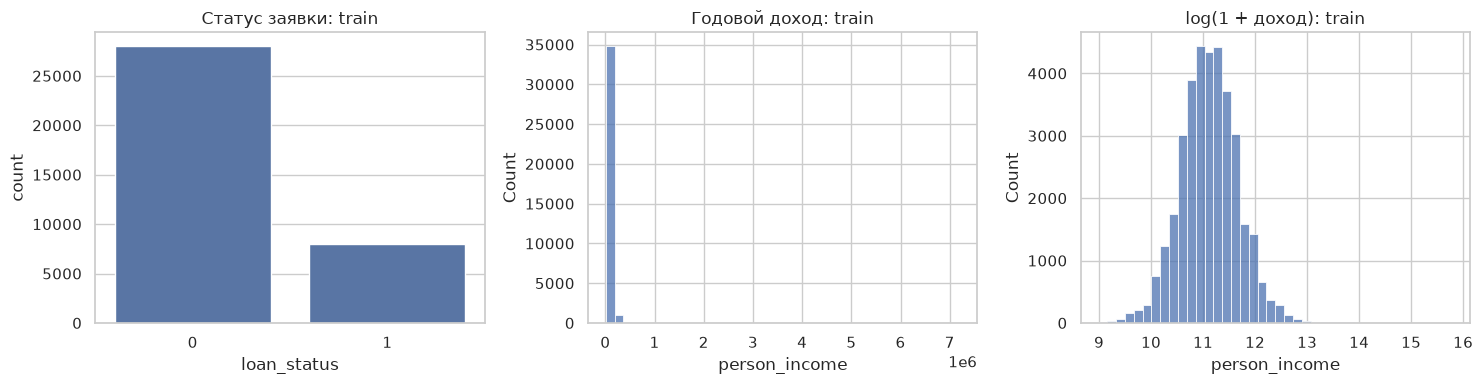

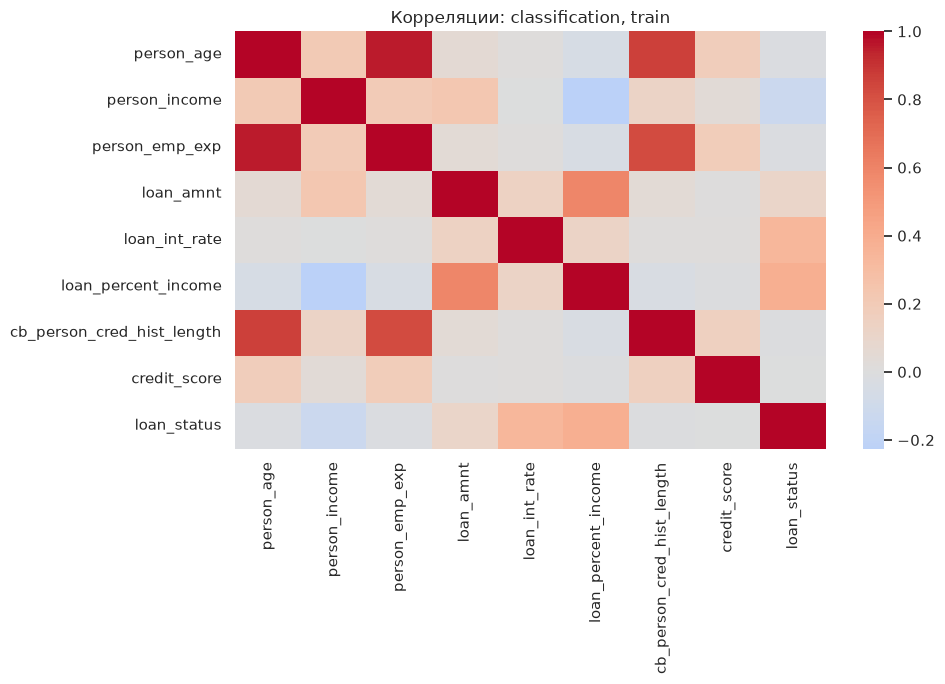

regression Concrete Compressive Strength


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.029847


,type,missing,unique
cement,float64,0,232
slag,float64,0,158
fly_ash,float64,0,133
water,float64,0,169
superplasticizer,float64,0,126
coarse_aggregate,float64,0,241
fine_aggregate,float64,0,255
age,int64,0,14
strength,float64,0,760


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
count,799.00,799.00,799.00,799.00,799.00,799.00,799.00,799.00,799.00
mean,277.63,70.22,55.93,182.55,5.82,974.05,772.96,47.58,34.97
std,102.50,87.40,63.97,21.43,5.71,73.81,83.14,67.01,15.81
min,108.30,0.00,0.00,121.75,0.00,801.00,594.00,1.00,2.33
25%,192.00,0.00,0.00,166.61,0.00,932.00,716.95,14.00,23.66
50%,266.00,15.00,0.00,185.70,6.00,968.00,780.58,28.00,33.72
75%,339.00,137.10,117.54,193.00,9.90,1025.00,829.75,56.00,44.47
max,540.00,359.40,200.10,246.90,32.20,1125.00,992.60,365.00,80.20


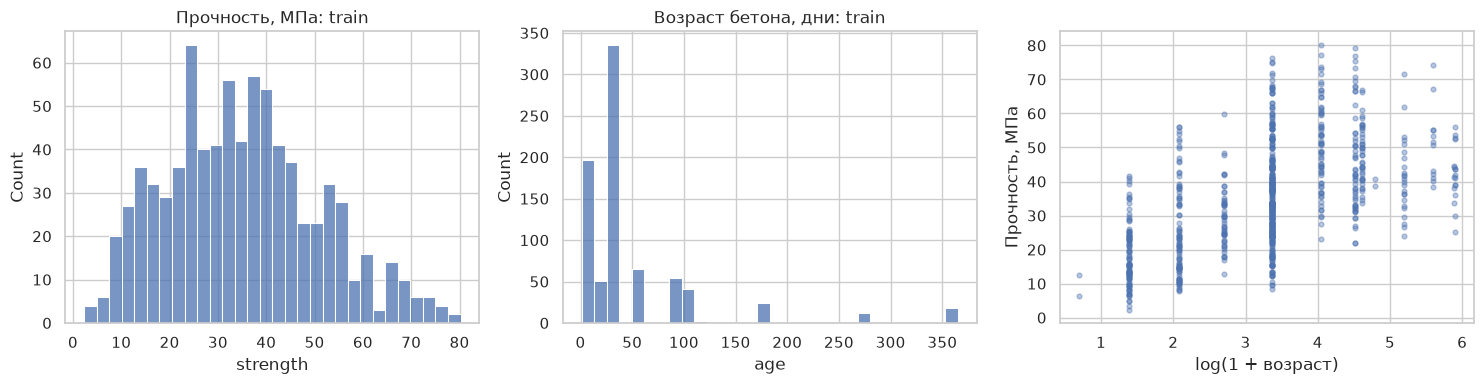

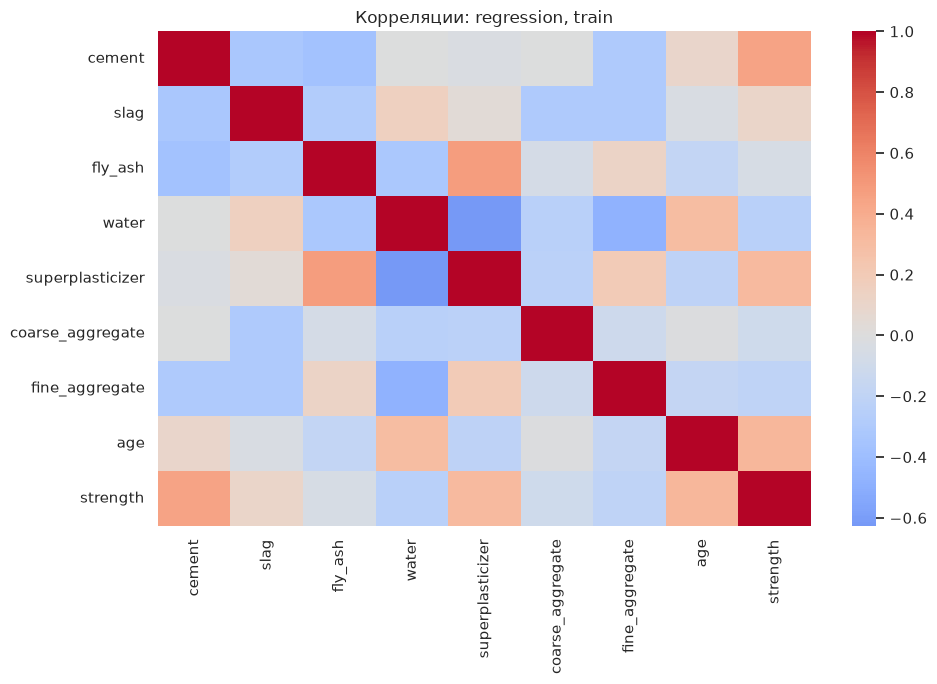

In [3]:
# Test не участвует в EDA и выборе преобразований.
for task, t in tasks.items():
    train = datasets[task].loc[t["train_idx"]]
    print(task, t["spec"]["name"])
    display(train.head())
    display(pd.DataFrame({"type": train.dtypes.astype(str), "missing": train.isna().sum(),
                          "unique": train.nunique()}))
    display(train.describe().round(2))
    if task == "classification":
        display(train["loan_status"].value_counts(normalize=True).rename("train_fraction"))
        print("Возраст >100:", int((train.person_age > 100).sum()),
              "; стаж >= возраста:", int((train.person_emp_exp >= train.person_age).sum()))
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        sns.countplot(data=train, x="loan_status", ax=axes[0])
        axes[0].set_title("Статус заявки: train")
        sns.histplot(train["person_income"], bins=40, ax=axes[1])
        axes[1].set_title("Годовой доход: train")
        sns.histplot(np.log1p(train["person_income"]), bins=40, ax=axes[2])
        axes[2].set_title("log(1 + доход): train")
    else:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        sns.histplot(train["strength"], bins=30, ax=axes[0])
        axes[0].set_title("Прочность, МПа: train")
        sns.histplot(train["age"], bins=30, ax=axes[1])
        axes[1].set_title("Возраст бетона, дни: train")
        axes[2].scatter(np.log1p(train["age"]), train["strength"], s=12, alpha=.4)
        axes[2].set(xlabel="log(1 + возраст)", ylabel="Прочность, МПа")
    plt.tight_layout()
    plt.show()
    fig, ax = plt.subplots(figsize=(10, 7))
    sns.heatmap(train.select_dtypes(include="number").corr(), cmap="coolwarm", center=0, ax=ax)
    ax.set_title(f"Корреляции: {task}, train")
    plt.tight_layout()
    plt.show()

## 2. Исходные модели sklearn
Исходный KNN использует k=5, равные веса соседей и евклидово расстояние.
Пропуски числовых признаков заполняются медианой, категориальных — наиболее частым значением;
категориальные признаки кодируются one-hot. Масштабирование в исходной конфигурации отсутствует.

Наивные ориентиры — DummyClassifier с наиболее частым классом и DummyRegressor с медианой цели.
На этом этапе рассчитано качество исходного KNN по кросс-валидации.
Итоговая оценка всех вариантов на отложенных выборках приведена в разделе 4.

In [4]:
# Фолды фиксированы и одинаковы для всех конфигураций внутри одной задачи.
cv = {"classification": list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(
          tasks["classification"]["X_train"], tasks["classification"]["y_train"])),
      "regression": list(GroupKFold(3).split(tasks["regression"]["X_train"],
          tasks["regression"]["y_train"], tasks["regression"]["groups_train"]))}
for train_fold, valid_fold in cv["regression"]:
    g = tasks["regression"]["groups_train"].to_numpy()
    assert set(g[train_fold]).isdisjoint(g[valid_fold])
scoring = {"classification": "f1", "regression": "neg_mean_absolute_error"}
base_models, hypothesis_records = {}, []
for task, t in tasks.items():
    base_models[task] = make_pipeline(t["X_train"], task, "raw")
    scores = cross_val_score(base_models[task], t["X_train"], t["y_train"],
                             cv=cv[task], scoring=scoring[task], n_jobs=1)
    hypothesis_records.append(dict(task=task, mode="raw", cv_mean=float(scores.mean()),
                                   cv_std=float(scores.std()), folds=scores.tolist()))
    print(task, "baseline CV:", scores, flush=True)

classification baseline CV: [0.56411342 0.56615776 0.57095228]


regression baseline CV: [-7.86501977 -7.38685628 -6.51967195]


## 3. Проверка гипотез и улучшение моделей

Проверены следующие гипотезы:

1. **H1 (`scaled`):** стандартизация числовых признаков уменьшает влияние различий масштаба на расстояние.
2. **H2 (`log`):** логарифмирование дохода в классификации и возраста в регрессии улучшает представление
   признаков с асимметричным распределением. После log1p применяется стандартизация.
3. **H3 (`engineered`):** дополнительные отношения признаков улучшают описание объектов.
   Для кредитов использованы стаж/возраст и кредитная история/возраст; для бетона — масса вяжущего
   `cement + slag + fly_ash`, отношение воды к вяжущему и отношение заполнителей к вяжущему.
   Дополнительные признаки не зависят от целевой переменной.
4. **H4:** подбор числа соседей, метрики расстояния и способа взвешивания повышает качество.
   Рассмотрены k∈{5,15,31}, weights∈{uniform,distance}, p∈{1,2}: 12 комбинаций для каждой задачи.

H1 сопоставлена с исходным вариантом, H2 — с H1, H3 — с H2.
Представление выбрано по среднему CV-score, после чего подобраны параметры KNN.
В классификации максимизируется F1, в регрессии минимизируется MAE.
Sklearn представляет MAE как отрицательную оценку, поэтому большее CV-score означает меньшую ошибку.
Во всех экспериментах использована полная обучающая выборка.

In [5]:
# Меняем по одному шагу preprocessing при неизменных k=5, weights=uniform, p=2.
for task, t in tasks.items():
    for mode in ["scaled", "log", "engineered"]:
        pipe = make_pipeline(t["X_train"], task, mode)
        scores = cross_val_score(pipe, t["X_train"], t["y_train"],
                                 cv=cv[task], scoring=scoring[task], n_jobs=1)
        hypothesis_records.append(dict(task=task, mode=mode, cv_mean=float(scores.mean()),
                                       cv_std=float(scores.std()), folds=scores.tolist()))
        print(task, mode, "CV mean:", scores.mean(), flush=True)
hypotheses = pd.DataFrame(hypothesis_records)
hypotheses.to_json(RESULTS / "hypotheses.json", orient="records", indent=2)
display(hypotheses.drop(columns="folds"))

classification scaled CV mean: 0.658284505469175


classification log CV mean: 0.6758198104641627


classification engineered CV mean: 0.675276596275749


regression scaled CV mean: -7.081122363594666


regression log CV mean: -5.789788759842254


regression engineered CV mean: -5.192995518002198


,task,mode,cv_mean,cv_std
0,classification,raw,0.567074,0.002866
1,regression,raw,-7.257183,0.556837
2,classification,scaled,0.658285,0.001416
3,classification,log,0.675820,0.007719
4,classification,engineered,0.675277,0.003568
5,regression,scaled,-7.081122,0.535004
6,regression,log,-5.789789,0.516837
7,regression,engineered,-5.192996,0.375107


### Подбор гиперпараметров
Поиск выполнен отдельно для каждой задачи на фиксированных CV-фолдах.
Рассчитаны средняя оценка и её стандартное отклонение по трём фолдам.
Отложенные выборки при выборе конфигураций не использованы.

In [6]:
# Подбираем параметры отдельно для классификации и регрессии.
searches, best_modes, selected = {}, {}, {}
for task, t in tasks.items():
    candidates = hypotheses[hypotheses.task == task]
    best_modes[task] = candidates.loc[candidates.cv_mean.idxmax(), "mode"]
    search = GridSearchCV(make_pipeline(t["X_train"], task, best_modes[task]),
                          {"model__n_neighbors": [5, 15, 31],
                           "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
                          scoring=scoring[task], cv=cv[task], n_jobs=1, refit=True,
                          return_train_score=False, error_score="raise")
    search.fit(t["X_train"], t["y_train"])
    searches[task] = search
    selected[task] = {"mode": best_modes[task], "params": search.best_params_,
                      "cv_score": float(search.best_score_)}
    pd.DataFrame(search.cv_results_).to_csv(RESULTS / f"cv_{task}.csv", index=False)
    print(task, selected[task], flush=True)
    display(pd.DataFrame(search.cv_results_)[["param_model__n_neighbors", "param_model__weights",
            "param_model__p", "mean_test_score", "std_test_score", "rank_test_score"]]
            .sort_values("rank_test_score").head(6))
(RESULTS / "selected.json").write_text(json.dumps(selected, ensure_ascii=False, indent=2))

classification {'mode': 'log', 'params': {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'distance'}, 'cv_score': 0.6914677878097462}


,param_model__n_neighbors,param_model__weights,param_model__p,mean_test_score,std_test_score,rank_test_score
5,15,distance,1,0.691468,0.006136,1
4,15,uniform,1,0.689462,0.006062,2
7,15,distance,2,0.688996,0.002555,3
6,15,uniform,2,0.688053,0.002200,4
9,31,distance,1,0.685878,0.003072,5
8,31,uniform,1,0.683663,0.001188,6


regression {'mode': 'engineered', 'params': {'model__n_neighbors': 5, 'model__p': 2, 'model__weights': 'distance'}, 'cv_score': -4.5027404039477075}


,param_model__n_neighbors,param_model__weights,param_model__p,mean_test_score,std_test_score,rank_test_score
3,5,distance,2,-4.502740,0.428883,1
1,5,distance,1,-4.635576,0.374747,2
7,15,distance,2,-5.187884,0.452136,3
2,5,uniform,2,-5.192996,0.375107,4
5,15,distance,1,-5.390569,0.477220,5
0,5,uniform,1,-5.584982,0.403443,6


389

### Результаты проверки гипотез
Разности CV-score отражают вклад каждого изменения предобработки и подбора параметров.
Положительное значение соответствует росту F1 либо снижению MAE.
Разброс по фолдам учитывается при интерпретации небольших различий.

In [7]:
# Выводы строятся из выполненных экспериментов, а не из ожидаемых результатов.
for task in tasks:
    h = hypotheses[hypotheses.task == task].set_index("mode")
    for new, old in [("scaled", "raw"), ("log", "scaled"), ("engineered", "log")]:
        delta = h.loc[new, "cv_mean"] - h.loc[old, "cv_mean"]
        unit = "F1" if task == "classification" else "МПа снижения MAE"
        print(f"{task}: {new} относительно {old}: Δ={delta:+.5f} {unit}")
    gain = searches[task].best_score_ - h.loc[best_modes[task], "cv_mean"]
    print(f"Подбор параметров: ΔCV-score={gain:+.5f}; выбран {best_modes[task]}")

classification: scaled относительно raw: Δ=+0.09121 F1
classification: log относительно scaled: Δ=+0.01754 F1
classification: engineered относительно log: Δ=-0.00054 F1
Подбор параметров: ΔCV-score=+0.01565; выбран log
regression: scaled относительно raw: Δ=+0.17606 МПа снижения MAE
regression: log относительно scaled: Δ=+1.29133 МПа снижения MAE
regression: engineered относительно log: Δ=+0.59679 МПа снижения MAE
Подбор параметров: ΔCV-score=+0.69026; выбран engineered


## 4. Собственная реализация KNN
Для каждого объекта вычисляется манхэттенское `Σ|x_j−z_j|` или евклидово `sqrt(Σ(x_j−z_j)²)`
расстояние до обучающих объектов, после чего выбираются k ближайших соседей.
В классификации применяется голосование, в регрессии — усреднение ответов.
При взвешивании по расстоянию используется вес `1/d`.

При нулевых расстояниях учитываются только точные совпадения. Равенство голосов разрешается
в пользу первого класса в отсортированном списке; при равных расстояниях на границе k
выбирается более ранний индекс обучающего объекта. Правило sklearn может отличаться.

Расстояния, поиск соседей и агрегация ответов реализованы на NumPy.
Из sklearn использованы интерфейс estimator и проверка входных данных.
Запросы обрабатываются пакетами, матрица расстояний имеет размер `batch_size × n_train`.
Временная сложность полного поиска — `O(n_test × n_train × d)`, дополнительная память — `O(batch_size × n_train)`.

In [8]:
# Собственная реализация: определения классов выполняются прямо в notebook.
"""KNN на NumPy: собственные расстояния, поиск соседей и агрегация ответов."""

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils.validation import check_is_fitted, validate_data


class _KNNBase(BaseEstimator):
    def __init__(self, n_neighbors=5, weights="uniform", p=2, batch_size=128):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.p = p
        self.batch_size = batch_size

    def _fit(self, X, y):
        if not isinstance(self.n_neighbors, (int, np.integer)) or self.n_neighbors < 1:
            raise ValueError("n_neighbors должен быть положительным целым")
        if self.weights not in ("uniform", "distance") or self.p not in (1, 2):
            raise ValueError("Поддерживаются uniform/distance и p=1/2")
        if not isinstance(self.batch_size, (int, np.integer)) or self.batch_size < 1:
            raise ValueError("batch_size должен быть положительным целым")
        X, y = validate_data(self, X, y, dtype=np.float64, ensure_2d=True)
        if y.ndim != 1:
            raise ValueError("Поддерживается одна целевая переменная")
        if self.n_neighbors > len(X):
            raise ValueError("Число соседей превышает размер обучающей выборки")
        # Копии защищают обученную модель от изменения исходных массивов.
        self.X_ = X.copy()
        self.y_ = y.copy()
        return self

    def _neighbors(self, X):
        check_is_fitted(self, ["X_", "y_"])
        X = validate_data(self, X, reset=False, dtype=np.float64)
        for start in range(0, len(X), self.batch_size):
            block = X[start:start + self.batch_size]
            # Накапливаем расстояние по признакам; не создаём тензор (B, N, D).
            distances = np.zeros((len(block), len(self.X_)), dtype=np.float64)
            for column in range(self.n_features_in_):
                delta = block[:, column, None] - self.X_[None, :, column]
                distances += np.abs(delta) if self.p == 1 else delta * delta
            # При совпадении расстояний на границе k выбираем ранний индекс train.
            # Быстрый argpartition дополнен явным разрешением граничных ничьих.
            indices = np.argpartition(distances, self.n_neighbors - 1, axis=1)[:, :self.n_neighbors]
            for row in range(len(block)):
                boundary = distances[row, indices[row]].max()
                closer = np.flatnonzero(distances[row] < boundary)
                equal = np.flatnonzero(distances[row] == boundary)
                indices[row] = np.concatenate((closer, equal[:self.n_neighbors - len(closer)]))
            selected = np.take_along_axis(distances, indices, axis=1)
            if self.p == 2:
                selected = np.sqrt(selected)
            if self.weights == "uniform":
                weights = np.ones_like(selected)
            else:
                zero = selected == 0
                # Если есть точные совпадения, учитываем только их, без деления на 0.
                weights = np.divide(1.0, selected, out=np.zeros_like(selected), where=~zero)
                has_zero = zero.any(axis=1)
                weights[has_zero] = zero[has_zero]
            yield indices, weights


class KNNClassifier(ClassifierMixin, _KNNBase):
    def fit(self, X, y):
        self._fit(X, y)
        self.classes_, self.encoded_y_ = np.unique(self.y_, return_inverse=True)
        return self

    def predict_proba(self, X):
        blocks = []
        for indices, weights in self._neighbors(X):
            labels = self.encoded_y_[indices]
            votes = np.column_stack([
                (weights * (labels == label)).sum(axis=1)
                for label in range(len(self.classes_))
            ])
            blocks.append(votes / weights.sum(axis=1, keepdims=True))
        return np.vstack(blocks)

    def predict(self, X):
        # np.argmax разрешает равенство голосов в пользу первого класса np.unique.
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class KNNRegressor(RegressorMixin, _KNNBase):
    def fit(self, X, y):
        self._fit(X, y)
        self.y_ = np.asarray(self.y_, dtype=np.float64)
        if not np.isfinite(self.y_).all():
            raise ValueError("y должен содержать конечные числа")
        return self

    def predict(self, X):
        return np.concatenate([
            (self.y_[indices] * weights).sum(axis=1) / weights.sum(axis=1)
            for indices, weights in self._neighbors(X)
        ])

### Обучение и оценка на отложенных выборках
Для каждой задачи сопоставлены Dummy, исходный и улучшенный sklearn KNN,
исходный и улучшенный собственный KNN. Собственные модели используют те же преобразования
и параметры, что и соответствующие модели sklearn.

Все модели обучены на полном train. Отдельно измерены время fit и время предсказания.
В классификации вероятности и классы получены за один проход по соседям.

In [9]:
# После фиксации настроек считаем holdout-метрики для каждой задачи на её датасете.
records, fitted, predictions = [], {}, {}
for task, t in tasks.items():
    own_cls = KNNClassifier if task == "classification" else KNNRegressor
    dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
    params = {key.replace("model__", ""): value for key, value in searches[task].best_params_.items()}
    models = {
        "dummy": make_pipeline(t["X_train"], task, "raw", dummy),
        "sklearn_baseline": clone(base_models[task]),
        "sklearn_improved": clone(searches[task].best_estimator_),
        "custom_baseline": make_pipeline(t["X_train"], task, "raw", own_cls()),
        "custom_improved": make_pipeline(t["X_train"], task, best_modes[task], own_cls(**params)),
    }
    feature_set = ",".join(t["X_train"].columns)
    for name, model in models.items():
        started = perf_counter()
        model.fit(t["X_train"], t["y_train"])
        fit_seconds = perf_counter() - started
        started = perf_counter()
        proba = None
        if task == "classification":
            probabilities = model.predict_proba(t["X_test"])
            prediction = model.classes_[probabilities.argmax(axis=1)]
            proba = probabilities[:, list(model.classes_).index(1)]
        else:
            prediction = model.predict(t["X_test"])
        predict_seconds = perf_counter() - started
        scores = evaluate(task, t["y_test"], prediction, proba)
        records.append(dict(lab=1, algorithm="Dummy" if name == "dummy" else "KNN", model=name,
                            implementation="custom" if name.startswith("custom") else "sklearn",
                            stage="dummy" if name == "dummy" else name.split("_")[1], task=task,
                            dataset=t["spec"]["name"], target=targets[task], feature_set=feature_set,
                            dataset_sha=t["spec"]["sha256"], split_sha=t["split_sha"],
                            protocol_id=t["spec"]["protocol_id"],
                            n_train=len(t["X_train"]), n_test=len(t["X_test"]),
                            fit_seconds=fit_seconds, predict_seconds=predict_seconds, **scores))
        fitted[task, name] = model
        predictions[task, name] = (prediction, proba)
        print(task, name, scores, flush=True)
metrics = pd.DataFrame(records)
metrics.to_csv(RESULTS / "metrics.csv", index=False)
for task in tasks:
    columns = ["model", "f1", "precision", "recall", "balanced_accuracy", "roc_auc", "average_precision"] if task == "classification" else ["model", "mae", "rmse", "r2"]
    display(metrics.loc[metrics.task == task, columns].round(5))

classification dummy {'f1': 0.0, 'precision': 0.0, 'recall': 0.0, 'balanced_accuracy': 0.5, 'accuracy': 0.7777777777777778, 'roc_auc': 0.5, 'average_precision': 0.2222222222222222}


classification sklearn_baseline {'f1': 0.5859265489206616, 'precision': 0.6668793873643906, 'recall': 0.5225, 'balanced_accuracy': 0.7239642857142856, 'accuracy': 0.8358888888888889, 'roc_auc': 0.8147027857142859, 'average_precision': 0.5943123816703744}


classification sklearn_improved {'f1': 0.6959686450167973, 'precision': 0.7907124681933843, 'recall': 0.6215, 'balanced_accuracy': 0.78725, 'accuracy': 0.8793333333333333, 'roc_auc': 0.9352203571428572, 'average_precision': 0.8303381184351784}


classification custom_baseline {'f1': 0.5859265489206616, 'precision': 0.6668793873643906, 'recall': 0.5225, 'balanced_accuracy': 0.7239642857142856, 'accuracy': 0.8358888888888889, 'roc_auc': 0.8147027857142859, 'average_precision': 0.5943123816703744}


classification custom_improved {'f1': 0.6959686450167973, 'precision': 0.7907124681933843, 'recall': 0.6215, 'balanced_accuracy': 0.78725, 'accuracy': 0.8793333333333333, 'roc_auc': 0.9352203571428572, 'average_precision': 0.8303381184351784}


regression dummy {'mae': 14.523307981976712, 'rmse': 18.155200713782826, 'r2': -0.021546723293346393}


... (2 outputs left out)

regression custom_baseline {'mae': 6.667497809001248, 'rmse': 9.146949252785749, 'r2': 0.7406963290108046}


regression custom_improved {'mae': 4.421757347285524, 'rmse': 6.7928852006152685, 'r2': 0.8569905698527297}


,model,f1,precision,recall,balanced_accuracy,roc_auc,average_precision
0,dummy,0.00000,0.00000,0.0000,0.50000,0.50000,0.22222
1,sklearn_baseline,0.58593,0.66688,0.5225,0.72396,0.81470,0.59431
2,sklearn_improved,0.69597,0.79071,0.6215,0.78725,0.93522,0.83034
3,custom_baseline,0.58593,0.66688,0.5225,0.72396,0.81470,0.59431
4,custom_improved,0.69597,0.79071,0.6215,0.78725,0.93522,0.83034


,model,mae,rmse,r2
5,dummy,14.52331,18.15520,-0.02155
6,sklearn_baseline,6.66750,9.14695,0.74070
7,sklearn_improved,4.41873,6.79240,0.85701
8,custom_baseline,6.66750,9.14695,0.74070
9,custom_improved,4.42176,6.79289,0.85699


### Анализ ошибок
Для улучшенного классификатора построены матрица ошибок, ROC-кривая и precision–recall кривая.
Для регрессии сопоставлены фактическая и предсказанная прочность, рассмотрены остатки.
Параметры моделей после анализа отложенных выборок не изменялись.

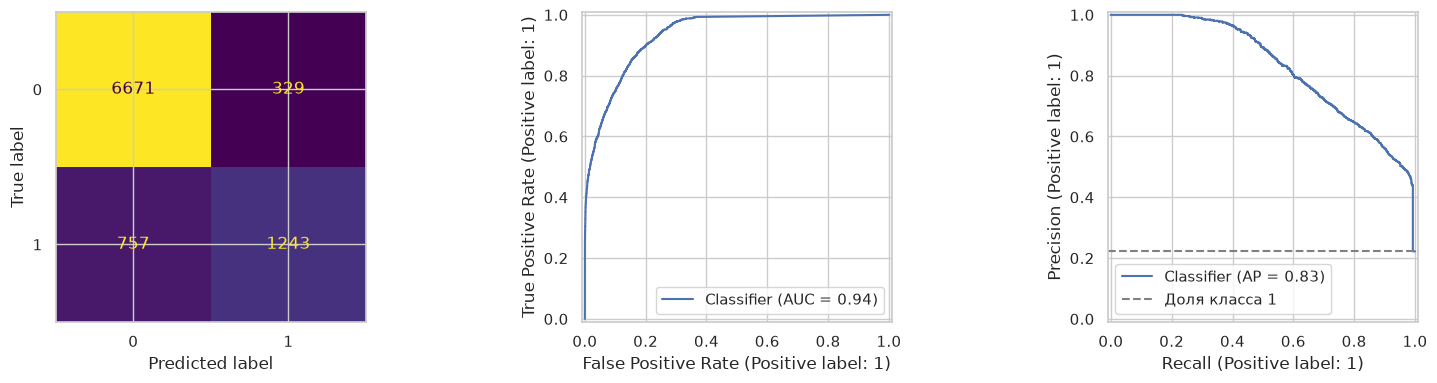

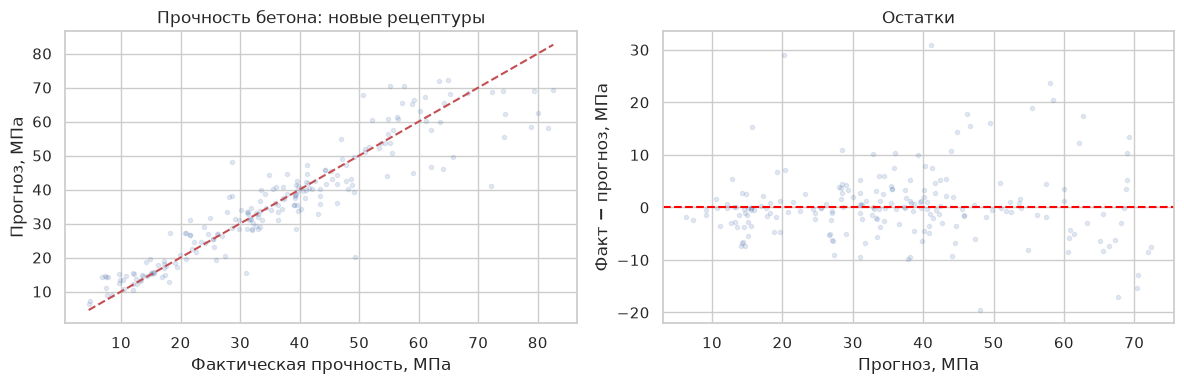

In [10]:
# Результаты не переиспользуются для дополнительного подбора модели.
truth = tasks["classification"]["y_test"]
pred, proba = predictions["classification", "sklearn_improved"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(truth, pred, ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(truth, proba, ax=axes[1])
PrecisionRecallDisplay.from_predictions(truth, proba, ax=axes[2])
axes[2].axhline(truth.mean(), color="gray", linestyle="--", label="Доля класса 1")
axes[2].legend()
plt.tight_layout()
plt.show()
truth_r = tasks["regression"]["y_test"]
pred_r, _ = predictions["regression", "sklearn_improved"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(truth_r, pred_r, alpha=.15, s=9)
axes[0].plot([truth_r.min(), truth_r.max()], [truth_r.min(), truth_r.max()], "r--")
axes[0].set(xlabel="Фактическая прочность, МПа", ylabel="Прогноз, МПа", title="Прочность бетона: новые рецептуры")
axes[1].scatter(pred_r, truth_r - pred_r, alpha=.15, s=9)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Прогноз, МПа", ylabel="Факт − прогноз, МПа", title="Остатки")
plt.tight_layout()
plt.show()

## 5. Сравнение результатов
Оценён эффект улучшений для sklearn, затем сопоставлены реализации при исходных
и выбранных параметрах. Отдельно рассмотрено улучшение собственной модели.
Для F1 положительная разность означает рост качества, для MAE — увеличение ошибки.

In [11]:
# Численные выводы строятся из выполненных экспериментов, включая сравнение с Dummy.
conclusions, agreements = [], {}
for task in tasks:
    m = metrics[metrics.task == task].set_index("model")
    metric = "f1" if task == "classification" else "mae"
    for left, right in [("sklearn_improved", "sklearn_baseline"),
                        ("custom_baseline", "sklearn_baseline"),
                        ("custom_improved", "sklearn_improved"),
                        ("custom_improved", "custom_baseline")]:
        delta = m.loc[left, metric] - m.loc[right, metric]
        text = f"{task}: {left} − {right}: Δ{metric}={delta:+.6f}"
        conclusions.append(text)
        print(text)
    agreements[task] = {}
    for stage in ["baseline", "improved"]:
        own = predictions[task, "custom_" + stage][0]
        ref = predictions[task, "sklearn_" + stage][0]
        difference = float(np.mean(own != ref)) if task == "classification" else float(np.mean(np.abs(own - ref)))
        agreements[task][stage] = difference
        print(stage, "доля разных классов" if task == "classification" else "среднее |различие прогнозов|, МПа", difference)
    if task == "classification":
        gain = m.loc["sklearn_improved", "f1"] - m.loc["sklearn_baseline", "f1"]
        verdict = "выше" if gain > 0 else "не выше"
        conclusions.append(f"F1 выбранного по CV варианта {verdict} исходного на holdout; Δ={gain:+.5f}.")
    else:
        gain = m.loc["sklearn_baseline", "mae"] - m.loc["sklearn_improved", "mae"]
        verdict = "снизилась" if gain > 0 else "не снизилась"
        dummy_gain = m.loc["dummy", "mae"] - m.loc["sklearn_improved", "mae"]
        conclusions.append(f"MAE {verdict}: снижение относительно исходного KNN {gain:+.3f} МПа, "
                           f"относительно Dummy {dummy_gain:+.3f} МПа; R²={m.loc['sklearn_improved', 'r2']:.4f}.")
display(Markdown("\n\n".join(conclusions)))
display(metrics[["task", "model", "fit_seconds", "predict_seconds"]].round(4))

classification: sklearn_improved − sklearn_baseline: Δf1=+0.110042
classification: custom_baseline − sklearn_baseline: Δf1=+0.000000
classification: custom_improved − sklearn_improved: Δf1=+0.000000
classification: custom_improved − custom_baseline: Δf1=+0.110042
baseline доля разных классов 0.0
improved доля разных классов 0.0
regression: sklearn_improved − sklearn_baseline: Δmae=-2.248764
regression: custom_baseline − sklearn_baseline: Δmae=+0.000000
regression: custom_improved − sklearn_improved: Δmae=+0.003024
regression: custom_improved − custom_baseline: Δmae=-2.245740
baseline среднее |различие прогнозов|, МПа 1.0347709744079128e-15
improved среднее |различие прогнозов|, МПа 0.0030238394639647533


classification: sklearn_improved − sklearn_baseline: Δf1=+0.110042

classification: custom_baseline − sklearn_baseline: Δf1=+0.000000

classification: custom_improved − sklearn_improved: Δf1=+0.000000

classification: custom_improved − custom_baseline: Δf1=+0.110042

F1 выбранного по CV варианта выше исходного на holdout; Δ=+0.11004.

regression: sklearn_improved − sklearn_baseline: Δmae=-2.248764

regression: custom_baseline − sklearn_baseline: Δmae=+0.000000

regression: custom_improved − sklearn_improved: Δmae=+0.003024

regression: custom_improved − custom_baseline: Δmae=-2.245740

MAE снизилась: снижение относительно исходного KNN +2.249 МПа, относительно Dummy +10.105 МПа; R²=0.8570.

,task,model,fit_seconds,predict_seconds
0,classification,dummy,0.0407,0.0075
1,classification,sklearn_baseline,0.0430,0.8542
2,classification,sklearn_improved,0.0448,3.2794
3,classification,custom_baseline,0.0428,40.2145
4,classification,custom_improved,0.0481,39.9489
5,regression,dummy,0.0029,0.0011
6,regression,sklearn_baseline,0.0025,0.0018
7,regression,sklearn_improved,0.0041,0.0028
8,regression,custom_baseline,0.0025,0.0055
9,regression,custom_improved,0.0037,0.0074


### Параметры эксперимента
Для каждой задачи зафиксированы исходный файл, целевой признак, состав входных признаков,
разбиение и выбранная конфигурация. Сохранены оценки CV, метрики отложенной выборки
и измеренные различия прогнозов двух реализаций.

In [12]:
# Фиксируем параметры, состав данных и независимые разбиения двух задач.
metadata = {"seed": SEED, "cv_folds": 3, "datasets": {}, "selected": selected,
            "selection": "full train CV only; preprocessing then grid; test reporting only",
            "versions": {"python": platform.python_version(), "numpy": np.__version__,
                         "pandas": pd.__version__, "sklearn": sklearn.__version__}}
for task, t in tasks.items():
    metadata["datasets"][task] = {
        "name": t["spec"]["name"], "file": t["spec"]["file"], "target": targets[task],
        "dataset_sha": t["spec"]["sha256"], "split_sha": t["split_sha"],
        "split_file": f"split_{task}.csv", "protocol_id": t["spec"]["protocol_id"],
        "excluded": t["spec"]["excluded"], "features": list(t["X_train"].columns),
        "duplicates_removed": t["duplicates_removed"], "n_train": len(t["X_train"]), "n_test": len(t["X_test"]),
        "holdout": "stratified rows 20%" if task == "classification" else "20% recipe groups, age excluded from group key",
        "cv": "StratifiedKFold(3)" if task == "classification" else "GroupKFold(3), recipe groups",
    }
(RESULTS / "protocol.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
(RESULTS / "agreement.json").write_text(json.dumps(agreements, indent=2))
(RESULTS / "conclusions.md").write_text("# Измеренные сравнения KNN\n\n" + "\n\n".join(conclusions) + "\n")
for path in sorted(RESULTS.iterdir()):
    if path.suffix != ".log":
        print(path.name)

agreement.json
conclusions.md
cv_classification.csv
cv_regression.csv
hypotheses.json
metrics.csv
protocol.json
selected.json
split.csv
split_classification.csv
split_regression.csv


### Сводные результаты
В таблице приведены исходные и улучшенные модели обеих реализаций.
MAE и RMSE регрессии измеряются в МПа, F1 классификации безразмерен.

In [13]:
# Компактная сводка обновляется при каждом выполнении notebook.
summary = metrics[metrics.model.isin(["sklearn_baseline", "sklearn_improved", "custom_baseline", "custom_improved"])][
    ["task", "dataset", "model", "f1", "mae", "rmse", "r2"]]
display(summary.round(5))
for task, config in selected.items():
    print(task, "выбранная конфигурация:", config)


,task,dataset,model,f1,mae,rmse,r2
1,classification,Loan Approval Classification Data,sklearn_baseline,0.58593,NaN,NaN,NaN
2,classification,Loan Approval Classification Data,sklearn_improved,0.69597,NaN,NaN,NaN
3,classification,Loan Approval Classification Data,custom_baseline,0.58593,NaN,NaN,NaN
4,classification,Loan Approval Classification Data,custom_improved,0.69597,NaN,NaN,NaN
6,regression,Concrete Compressive Strength,sklearn_baseline,NaN,6.66750,9.14695,0.74070
7,regression,Concrete Compressive Strength,sklearn_improved,NaN,4.41873,6.79240,0.85701
8,regression,Concrete Compressive Strength,custom_baseline,NaN,6.66750,9.14695,0.74070
9,regression,Concrete Compressive Strength,custom_improved,NaN,4.42176,6.79289,0.85699


classification выбранная конфигурация: {'mode': 'log', 'params': {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'distance'}, 'cv_score': 0.6914677878097462}
regression выбранная конфигурация: {'mode': 'engineered', 'params': {'model__n_neighbors': 5, 'model__p': 2, 'model__weights': 'distance'}, 'cv_score': -4.5027404039477075}


### Обсуждение результатов

Классификации помогли масштабирование и логарифмирование дохода; отношения стажа и кредитной
истории к возрасту не повысили средний CV F1. Выбран `log`, k=15, p=1, `distance`.
На holdout F1 вырос на 0.11004.

В регрессии масштабирование дало небольшой выигрыш CV, логарифм возраста и признаки состава — более заметный.
Выбран `engineered`, k=5, p=2, `distance`. MAE на новых рецептурах снизилась с
6.667 до 4.419 МПа
(33.73%).
Dummy с медианой даёт MAE 14.523 МПа: KNN использует информацию о составе и возрасте,
а не только средний уровень прочности. После удаления 25 дубликатов train содержит 799 измерений
342 рецептур, test — 206 измерений 86 других рецептур.

В классификации обе собственные модели предсказали те же классы, что и соответствующие sklearn-модели.
Для регрессии baseline совпал с точностью округления; в улучшенном варианте разность MAE составляет
0.003024 МПа. Диагностика выявила один отличающийся
прогноз из 206 (позиция 5, исходная строка 60): sklearn 53.605101, собственный KNN 52.982190 МПа.
Два альтернативных соседа на границе k имеют практически равные квадраты расстояний
0.45680277270159825 и 0.45680277270159814. Результат зависит от округления и выбора граничного соседа;
это согласуется с документированным правилом ничьих. Подробности: `results/tie_diagnostic.json`.

Собственный поиск работает медленнее sklearn. В проведённом эксперименте улучшенная классификация заняла
39.95 против 3.28 с при прогнозе;
небольшой регрессионный набор — 0.0074 против
0.0028 с. Короткий fit отражает запоминание train.
Результаты относятся к одному holdout и не доказывают универсального превосходства конфигурации.


### Ограничения исследования
KNN чувствителен к масштабу, кодированию, числу признаков и плотности обучающих данных.
Малое время fit означает запоминание train; полный поиск соседей требует времени при прогнозе.
Измерения скорости относятся к текущему окружению и не являются универсальным рейтингом производительности.

Для банковских данных сохраняются ограничения синтетического происхождения и потенциальная зависимость
созданных SMOTENC объектов. Для бетона один holdout и относительно небольшой объём данных ограничивают
точность выводов. Группировка предотвращает пересечение точно совпадающих рецептур;
она не доказывает независимость всех лабораторных измерений или близких составов.
Социальные признаки банковского набора требуют отдельной проверки справедливости при практическом применении.
Прогноз прочности не заменяет лабораторные испытания материала.

Собственная реализация сравнивается при тех же параметрах и преобразованиях. Возможные небольшие отличия
объясняются численной точностью и правилами разрешения равных расстояний; в notebook приведены измеренные
различия, без предположения об обязательном совпадении. Тесты `tests/test_knn.py` проверяют p=1/2,
uniform/distance, нулевые расстояния, ничьи и валидацию входов.

**Источники:** [Kaggle, taweilo](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data),
[фиксированная копия Loan Approval](https://github.com/dpidaparthi/loan-approval-classification/blob/379a24f61cd5d9f032415b14a5797f30cf1d4a05/data/loan_data.csv),
[UCI Concrete Compressive Strength, Yeh (1998), DOI 10.24432/C5PK67](https://doi.org/10.24432/C5PK67),
[описание KNN в sklearn](https://scikit-learn.org/stable/modules/neighbors.html).
Происхождение, лицензия UCI и SHA256 указаны в `data/README.md`.